# EJERCICIO 1

### APARTADO 1

Realice una gráfica de el aumento del desempleo frente a la ley de Okun, y realice la pertinente regresión lineal.

In [1]:
import pandas as pd

ruta = r"C:\Users\jose carlos\OneDrive - Universidad Complutense de Madrid (UCM)\Documentos\Universidad\Quinto\Macro\Entrega 3\Datos ejercicio 1.xlsx"

#Importamos los datos, que como vemos abajo incluyen el año, la tasa de desempleo y el PIB real.
data = pd.read_excel(ruta)   
print(data.head())
print(data.dtypes)




    Año     PIB  TASA DE PARO
0  1980  124162         9.706
1  1980  124585        10.425
2  1980  124091        10.905
3  1980  124811        11.540
4  1981  124107        12.168
Año               int64
PIB               int64
TASA DE PARO    float64
dtype: object


In [2]:
#Eliminamos los datos del primer, segundo y tercer trimestre para quedarnos solo con los datos anuales (cuarto trimestre)
data_trim4 = data[3::4].reset_index(drop=True)

# Tasa de crecimiento del PIB (porcentual)
data_trim4['Tasa_Crecimiento_PIB'] = data_trim4['PIB'].pct_change() * 100

# Cambio absoluto del desempleo (NO porcentual)
data_trim4['Cambio_Absoluto_Desempleo'] = data_trim4['TASA DE PARO'].diff()

print(data_trim4[['Año', 
                   'Tasa_Crecimiento_PIB', 'Cambio_Absoluto_Desempleo']])


     Año  Tasa_Crecimiento_PIB  Cambio_Absoluto_Desempleo
0   1980                   NaN                        NaN
1   1981             -0.332503                      2.311
2   1982              1.827229                      1.467
3   1983              1.788125                      1.157
4   1984              1.521709                      2.779
5   1985              3.239213                      0.252
6   1986              2.598863                     -0.978
7   1987              7.875339                     -0.812
8   1988              3.147753                     -1.393
9   1989              4.576244                     -1.558
10  1990              6.152416                     -0.946
11  1991              0.522594                      0.582
12  1992             -0.905574                      2.591
13  1993              0.628968                      3.049
14  1994              2.232190                     -0.102
15  1995              2.948684                     -0.913
16  1996      

In [3]:
#Ahora calculamos la ley de Okun
import statsmodels.api as sm

#Eliminamos los valores NA para hacer la regresión
df_reg = data_trim4[['Tasa_Crecimiento_PIB', 'Cambio_Absoluto_Desempleo']].dropna()
#Hacemos la regresión lineal
X = df_reg['Tasa_Crecimiento_PIB']
y = df_reg['Cambio_Absoluto_Desempleo']
X = sm.add_constant(X)  
modelo = sm.OLS(y, X).fit()
print(modelo.summary())

                                OLS Regression Results                               
Dep. Variable:     Cambio_Absoluto_Desempleo   R-squared:                       0.532
Model:                                   OLS   Adj. R-squared:                  0.521
Method:                        Least Squares   F-statistic:                     45.54
Date:                       Wed, 19 Nov 2025   Prob (F-statistic):           4.21e-08
Time:                               14:17:48   Log-Likelihood:                -72.340
No. Observations:                         42   AIC:                             148.7
Df Residuals:                             40   BIC:                             152.2
Df Model:                                  1                                         
Covariance Type:                   nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

In [4]:
#Comprobamos la heterocedasticidad con el test de White
from statsmodels.stats.diagnostic import het_white
white_test = het_white(modelo.resid, modelo.model.exog)
print('p-valor del test de White', white_test[1]) 

p-valor del test de White 0.0007559443294673547


El test de White tiene como hipótesis:


H₀: No hay heterocedasticidad (la varianza de los errores es constante).

H₁: Hay heterocedasticidad (la varianza de los errores no es constante).

Puesto que el valor del p valor del Test de White es claramente menor que 0.05 concluimos que sí hay heterocedasticidad en este modelo.

In [5]:
#Ahora comprobamos la autocorrelación con el test de Durbin-Watson
from statsmodels.stats.stattools import durbin_watson
dw = durbin_watson(modelo.resid)
print("Durbin-Watson:", dw)

#Ahora hacemos el test de Breusch-Godfrey para autocorrelación de orden superior
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
bg_test = acorr_breusch_godfrey(modelo, nlags=4)
print(f"El estadístico LM del test es {bg_test[0]:.4f} y su p-valor asociado es {bg_test[1]:.4f}.")
print(f"Además, el estadístico F es {bg_test[2]:.4f} con un p-valor de {bg_test[3]:.4f}.")


Durbin-Watson: 0.9236606785113171
El estadístico LM del test es 17.0285 y su p-valor asociado es 0.0019.
Además, el estadístico F es 6.1373 con un p-valor de 0.0007.


#### Resumen del test de Durbin–Watson (DW)

El test de Durbin–Watson sirve para comprobar si los residuos del modelo están autocorrelados en primer orden, es decir, si un error tiende a parecerse al del periodo anterior.
El estadístico siempre va entre 0 y 4:

≈ 2 → no hay autocorrelación

< 2 → autocorrelación positiva

\> 2 → autocorrelación negativa

Como encontramos un valor mucho menor que dos entendemos que sí hay autocorrelación positiva.

#### Resumen del test de Breusch–Godfrey (BG)

El test de Breusch–Godfrey es una versión más completa para detectar autocorrelación de cualquier orden, no solo de primer orden. Con las siguientes hipótesis:

H₀: No hay autocorrelación de los residuos hasta el orden 
𝑘.

H₁: Hay autocorrelación de los residuos de algún orden 
≤
𝑘.

Como los p-valores me dan muy bajos debemos rechazar la hipótesis nula y asegurar que existe autocorrelación de orden menor que 4.

## Realizamos un modelo con errores HAC.

In [6]:
#Hacemos el modelo con errores HAC
modelo_hac = modelo.get_robustcov_results(cov_type='HAC', maxlags=4)
print(modelo_hac.summary())

                                OLS Regression Results                               
Dep. Variable:     Cambio_Absoluto_Desempleo   R-squared:                       0.532
Model:                                   OLS   Adj. R-squared:                  0.521
Method:                        Least Squares   F-statistic:                     16.11
Date:                       Wed, 19 Nov 2025   Prob (F-statistic):           0.000255
Time:                               14:17:48   Log-Likelihood:                -72.340
No. Observations:                         42   AIC:                             148.7
Df Residuals:                             40   BIC:                             152.2
Df Model:                                  1                                         
Covariance Type:                         HAC                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

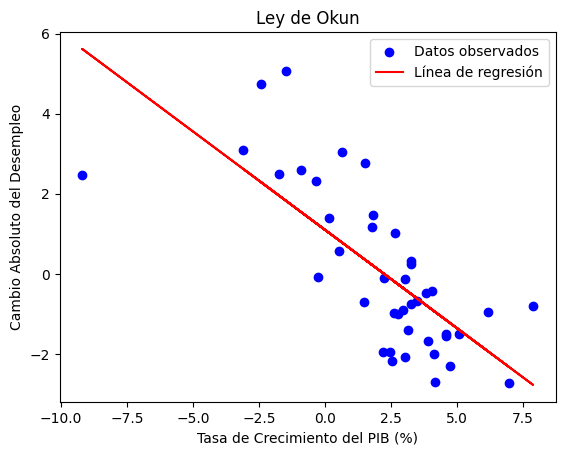

In [7]:
#Generamos el gráfico de modelos HAC
import matplotlib.pyplot as plt
plt.scatter(df_reg['Tasa_Crecimiento_PIB'], df_reg['Cambio_Absoluto_Desempleo'], color='blue', label='Datos observados')
plt.plot(df_reg['Tasa_Crecimiento_PIB'], modelo_hac.predict(X), color='red', label='Línea de regresión')
plt.xlabel('Tasa de Crecimiento del PIB (%)')
plt.ylabel('Cambio Absoluto del Desempleo')
plt.title('Ley de Okun')
plt.legend()
plt.show()

#### Conclusiones del modelo con errores HAC

El modelo estimado con errores estándar HAC muestra una relación negativa entre la Tasa de Crecimiento del PIB y el cambio en el desempleo. Un aumento de un punto porcentual en el crecimiento del PIB se asocia con una reducción aproximada de 0.49 puntos en el desempleo.
El coeficiente es estadísticamente significativo, lo que indica una relación clara entre ambas variables.

La constante también resulta significativa, reflejando un crecimiento del desempleo en ausencia de expansión económica.
La corrección HAC permite obtener inferencias válidas en presencia de heterocedasticidad y autocorrelación, por lo que las estimaciones resultan más fiables desde el punto de vista estadístico. Además se ve que como decía Okun para que no haya crecimiento del desempleo el crecimiento ha de estar en el 2,5%, (en este caso 2,2%) y la pendiente aproximada del 0,5 es la predicha por Okun que dijo que por cada punto de desempleo que deseara bajarse, iba a ser necesario subir dos puntos en el PIB.

### APARTADO 2

Haga una gráfica que muestre la evolución de la variación absoluta de la tasa de paro y de la tasa de paro para España, Reino Unido, Estados
Unidos, Alemania, Unión Europea y OCDE

C:\Users\jose carlos\AppData\Local\Temp\ipykernel_5848\932894625.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data2 = data2.replace("-", np.nan)


    ESPAÑA SERIES
0   10.703   2000
1   10.012   2001
2   11.033   2002
3   10.905   2003
4   10.144   2004
5    8.463   2005
6    8.034   2006
7    8.351   2007
8   13.412   2008
9   18.159   2009
10  19.546   2010
11  22.039   2011
12  25.143   2012
13  25.072   2013
14  23.123   2014
15  20.431   2015
16  18.245   2016
17  16.178   2017
18  14.212   2018
19  13.508   2019
20  15.965   2020
21  13.247   2021
22  12.770   2022
0     11.033
1     10.905
2     10.144
3      8.463
4      8.034
5      8.351
6     13.412
7     18.159
8     19.546
9     22.039
10    25.143
11    25.072
12    23.123
13    20.431
14    18.245
15    16.178
16    14.212
17    13.508
18    15.965
19    13.247
20    12.770
Name: ESPAÑA, dtype: float64


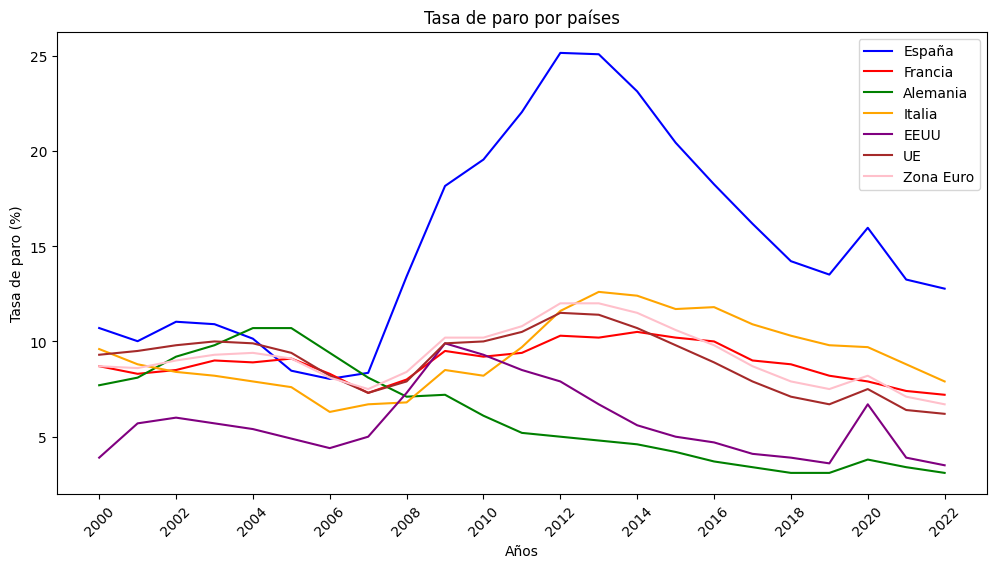

In [8]:
import numpy as np
from pandas import Series

#Sacamos nuestros datos del segundo apartado
data2 = pd.read_excel(ruta, sheet_name='Datos apartado 2')

# Reemplazar "-" por NaN, ya que los datos escogidos representan los faltantes con "-"
data2 = data2.replace("-", np.nan)

# Si quieres eliminar todas las filas que tengan NA
data2 = data2.dropna().reset_index(drop=True)

#Me quedo solo con los años escogiendo el último mes
data2_anual = data2[11::12].reset_index(drop=True)


#Cambio las etiquetas de los meses para que aparezcan solamente los años
# Año = primeros 4 dígitos
data2_anual['SERIES'] = data2_anual['SERIES'].astype(str)
years = data2_anual['SERIES'].str[:4]
data2_anual['SERIES'] = years.astype(str)

#Añado los datos de España
datos_españa=data[(data['Año'] >= 2000) & (data['Año']<=2022)].reset_index(drop=True)
datos_españa=datos_españa['TASA DE PARO'].iloc[3::4].reset_index(drop=True)

data2_anual['ESPAÑA'] = datos_españa.reset_index(drop=True)
data2_anual=data2_anual.dropna().reset_index(drop=True)
print(data2_anual[['ESPAÑA','SERIES']])
print(data2_anual['ESPAÑA'][(data2_anual['SERIES'] >= '2002') & (data2_anual['SERIES']<='2024')].reset_index(drop=True))
#Hago una represntación gráfica de todos los países
plt.figure(figsize=(12,6))
plt.plot(data2_anual['SERIES'], data2_anual['ESPAÑA'], label='España', color='blue')
plt.plot(data2_anual['SERIES'], data2_anual['FRANCIA'], label='Francia', color='red')
plt.plot(data2_anual['SERIES'], data2_anual['ALEMANIA'], label='Alemania', color='green')
plt.plot(data2_anual['SERIES'], data2_anual['ITALIA'], label='Italia', color='orange')
plt.plot(data2_anual['SERIES'], data2_anual['EEUU'], label='EEUU', color='purple')
plt.plot(data2_anual['SERIES'], data2_anual['UE'], label='UE', color='brown')
plt.plot(data2_anual['SERIES'], data2_anual['ZONA EURO'], label='Zona Euro', color='pink')
plt.xlabel('Años')
plt.ylabel('Tasa de paro (%)')
plt.title('Tasa de paro por países')
plt.xticks(data2_anual['SERIES'].iloc[::2], rotation=45)
plt.legend()
plt.show()

Aquí vemos como hay diferencias claras en los niveles de desempleo entre los países. En primer lugar, como tónica general, vemos que la crisis de 2008 dispara el desempleo en todos los países, así como en 2020. Dentro de cada país encontramos como la tasa de paro de España por ejemplo es sustancialmente mayor que la del resto de países. Le siguen por lo general Francia e Italia, y poco después Alemania y Estados Unidos son las que presentan niveles de desempleo más bajo. Pasando a la Zona Euro y la Unión Europea vemos patrones mas suavizados derivados de agregar muchos más países al mismo tiempo con la Unión Europea por debajo de la Zona Euro, consecuencia de que en la UE encontramos países con niveles de empleo más bajo como algunos países escandinavos. 

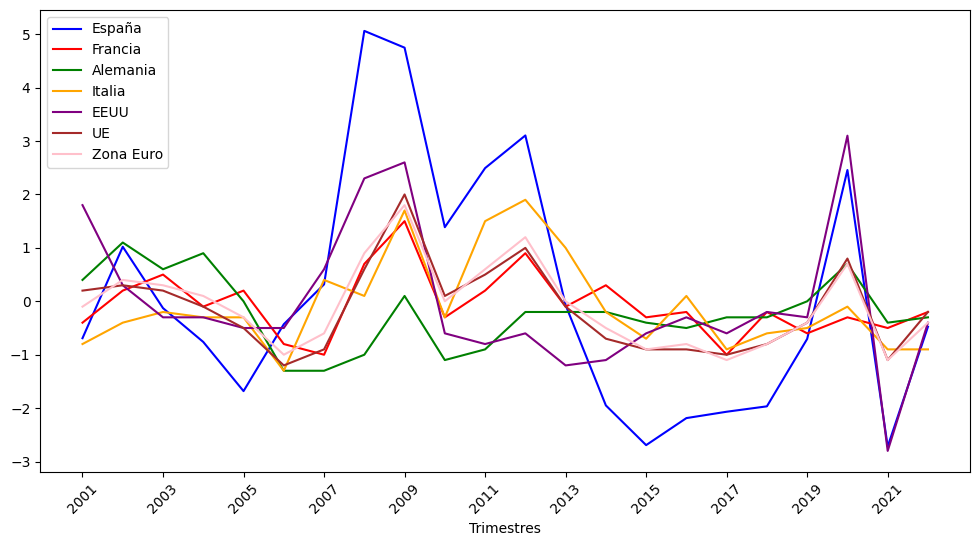

In [9]:
#Calculo las diferencias
data2_anualdiff = pd.DataFrame()
data2_anualdiff['Año'] = data2_anual['SERIES']
for country in ['ESPAÑA', 'FRANCIA', 'ALEMANIA', 'ITALIA', 'EEUU', 'UE', 'ZONA EURO']:
    data2_anualdiff[country] = data2_anual[country].diff()
data2_anualdiff = data2_anualdiff.dropna().reset_index(drop=True)
#Hago una represntación gráfica de todos los países de las diferencias
plt.figure(figsize=(12,6))
plt.plot(data2_anualdiff['Año'], data2_anualdiff['ESPAÑA'], label='España', color='blue')
plt.plot(data2_anualdiff['Año'], data2_anualdiff['FRANCIA'], label='Francia', color='red')
plt.plot(data2_anualdiff['Año'], data2_anualdiff['ALEMANIA'], label='Alemania', color='green')
plt.plot(data2_anualdiff['Año'], data2_anualdiff['ITALIA'], label='Italia', color='orange')
plt.plot(data2_anualdiff['Año'], data2_anualdiff['EEUU'], label='EEUU', color='purple')
plt.plot(data2_anualdiff['Año'], data2_anualdiff['UE'], label='UE', color='brown')
plt.plot(data2_anualdiff['Año'], data2_anualdiff['ZONA EURO'], label='Zona Euro', color='pink')
plt.xlabel('Trimestres')
plt.xticks(data2_anualdiff['Año'].iloc[::2], rotation=45)
plt.legend()
plt.show()

En los cambios interanuales encontramos unos patrones similares a los valores absolutos con picos muy grandes en los años cercanos a la crisis de 2008 de 2020. Igualmente España tiene unos patrones más exagerado al igual que Estados Unidos. El nivel de cambios tan alto del segundo sorprende porque sus valores en absolutos eran bajos por lo general. Esto se debe a que el país norteamericano tiene un mercado laboral mucho más flexible favoreciendo el despido y tambien la contratación, con políticas públicas orientadas a mantener los ingresos y no tanto el empleo.

Destaca también que Alemania durante la crisis de 2008 se sitúa por debajo del resto de países ya que en primer lugar favorecieron la reducción de horas en lugar de los despidos y derivado también de que venían de un nivel de paro más alto que el normal siendo el que mayor nivel tiene en años entorno al 2004 porque sufre una crisis muy fuerte de competitividad a comienzos de siglo derivado de la entrada del euro y de la reciente unificación.

### APARTADO 3

Calcule y represente la autocorrelación de horizonte 1, 2 y 3.

In [10]:
from statsmodels.tsa.stattools import acf

serie = data2_anual['ESPAÑA']

# Autocorrelación hasta lag 3 
autocorrs = acf(serie, nlags=3)

for i in range(1,4):
    print(f"Autocorrelación lag {i}:", autocorrs[i])



Autocorrelación lag 1: 0.8947435834439853
Autocorrelación lag 2: 0.6952284732614218
Autocorrelación lag 3: 0.47039650291829643


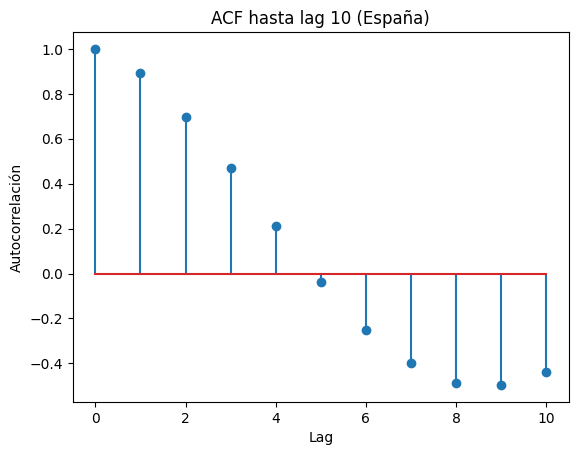

In [11]:
from statsmodels.tsa.stattools import acf
import matplotlib.pyplot as plt

# Calculamos la ACF hasta lag 10
acf_vals = acf(data2_anual['ESPAÑA'], nlags=10)

# Graficamos
plt.stem(range(len(acf_vals)), acf_vals)
plt.xlabel("Lag")
plt.ylabel("Autocorrelación")
plt.title("ACF hasta lag 10 (España)")
plt.show()


Si vemos el gráfico de España vemos como hay una fuerte correlación en los primeros lags, algo lógico en la tasa de paro ya que es una variable stock. Esta correlación va reduciéndose al avanzar en los años hasta que en el lag 5 comienza a ser negativa, cuando la correlación comienza a ser negativa siendo cercana a -0.5 en algunos de los años. Si comparamos con la serie danesa y estadounidense encontramos un patrón muy similar, al comienzo aunque sí es cierto que en ambos casos las correlaciones descienden mucho más despacio. Esto se puede explicar indicando que tienen unos ciclos menos marcados, y es que como hemos visto previamente la serie española de desempleo tiene subidas relativamente periódicas ya que nuestro mercado laboral tiende a ajustarse mucho via reducción de empleados y no tanto con reducción de horas y es un mercado donde la actividad es mucho menor.

### APARTADO 4
Realice el gráfico que relaciona la tasa de paro a largo plazo (más de seis meses) con la tasa de paro general y compárelo con el caso de Estados Unidos y Dinamarca.

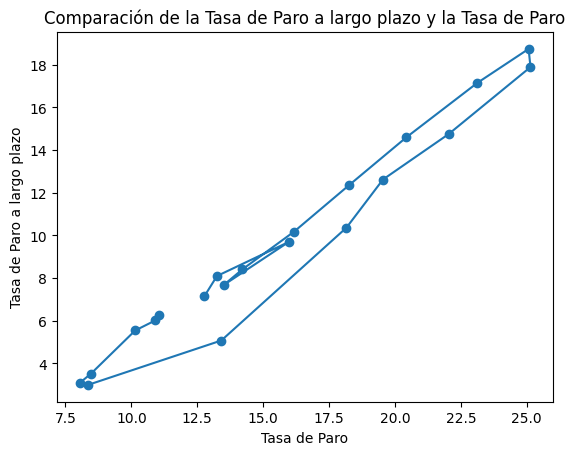

In [12]:
data4=pd.read_excel(ruta, sheet_name='Datos apartado 4')
data4_anual = data4[3::4].reset_index(drop=True)
data4_anual['Paro a largo plazo'] = data4_anual[['6M-1A', '1A-2A', '>2A']].sum(axis=1)
data4_anual['Tasa de Paro a largo plazo'] = data4_anual['Paro a largo plazo'] / data4_anual['OCUPADOS']*100
#Cojo la tasa de paro de España para los años entre 2002 y 2024
data4_anual['Tasa de Paro'] = data2_anual['ESPAÑA'][(data2_anual['SERIES'] >= '2002') & (data2_anual['SERIES']<='2024')].reset_index(drop=True)
#Hago la representación gráfica de tasa de paro a largo plazo en el eje y, tasa de paro normal en el eje x uniendo con lineas los puntos
plt.plot(data4_anual['Tasa de Paro'], data4_anual['Tasa de Paro a largo plazo'], marker='o')
plt.xlabel('Tasa de Paro')
plt.ylabel('Tasa de Paro a largo plazo')
plt.title('Comparación de la Tasa de Paro a largo plazo y la Tasa de Paro')
plt.show()

Vemos al igual que ocurre en el caso de Dinamarca y de Estados Unidos una relación positiva entre el paro a largo plazo y la tasa de paro general de la economía que en este casoes más empinada. Esta mayor empinación en el caso español denota un problema en España donde cuando el paro crece lo hace sobre todo de gente que no es capaz de encontrar una solución para la gente que más tiempo lleva sin trabajar. Esto es porque tenemos un mercado laboral más rígido que a diferencia del danés y del estadounidense sufre más a la hora de encontrar dinamismo.

### Apartado 5
Represente la tasa de desempleo por niveles educativos y compárelas con el caso danés y estadounidense.

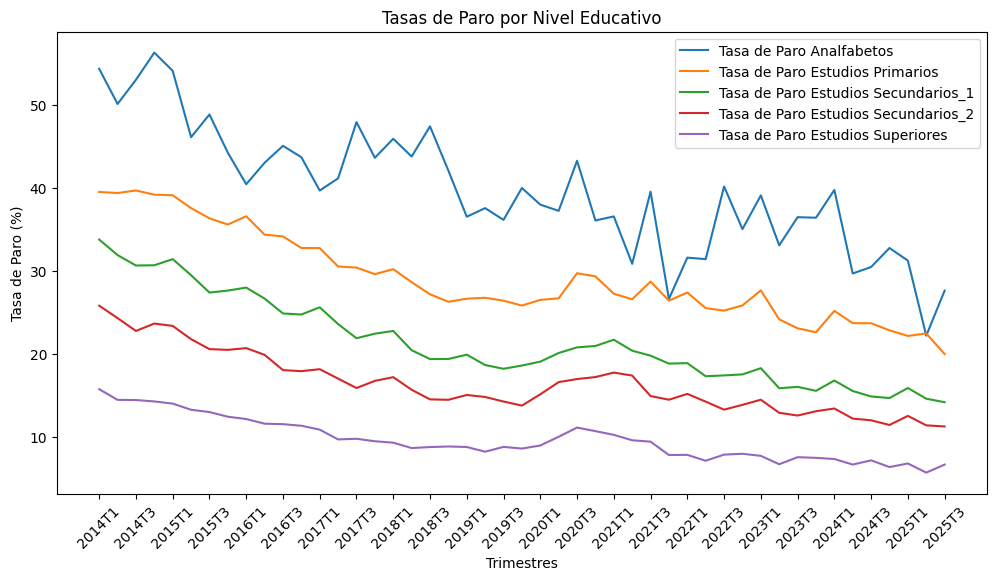

In [13]:
data5=pd.read_excel(ruta, sheet_name='Datos apartado 5')
#Cambiamos los trimestres a formato AñoT
#Pasamos los años a variable string
data5['Año'] = data5['Año'].astype(str)
years = data5['Año'].str[:4]
trimestres = data5['Año'].str[4:]
data5['Año'] = years + 'T' + trimestres
#Dibujamos las series temporales de las variables tasas de paro de niveles educativos
plt.figure(figsize=(12,6))
for i in data5.columns[1:]:
    plt.plot(data5['Año'], data5[i], label=i)
plt.xlabel('Trimestres')
plt.xticks(data5['Año'].iloc[::2], rotation=45)
plt.ylabel('Tasa de Paro (%)')
plt.title('Tasas de Paro por Nivel Educativo')
plt.legend()
plt.show()


La primera diferencia que se observa comn el caso estadounidense y danés es la diferencia de medición. Mientras que el libro divide únicamente en tres estratos la basee de datos consultada lo hace en cinco teniendo que interpretar el gráfico de una manera más general. La primera similitud es que, como es lógico, el desempleo en el caso de personas más formadas se va haciendo menor a medida que la eduación va aumentando y además el gráfico se va haciendo menos pronunciado. Estas diferencias se hacen mucho más notorias en el caso de España, haciendo que incluso en los mejores periodos los estractos de educación más baja siguen teniendo tasas de paro muy altas mientras que los de educación más alta lo tienen más parecidos a los otros dos países. Igualmente en España vemos picos más altos en los estractos de educación más bajos relacionados probablemente con que ese empleo es más sensible al ciclo económico, y esto se exagera en España porque los grupos son más concretos.

## APARTADO 6

Realice un gráfico de la tasa de paro de las distintas comunidades autónomas y comente.

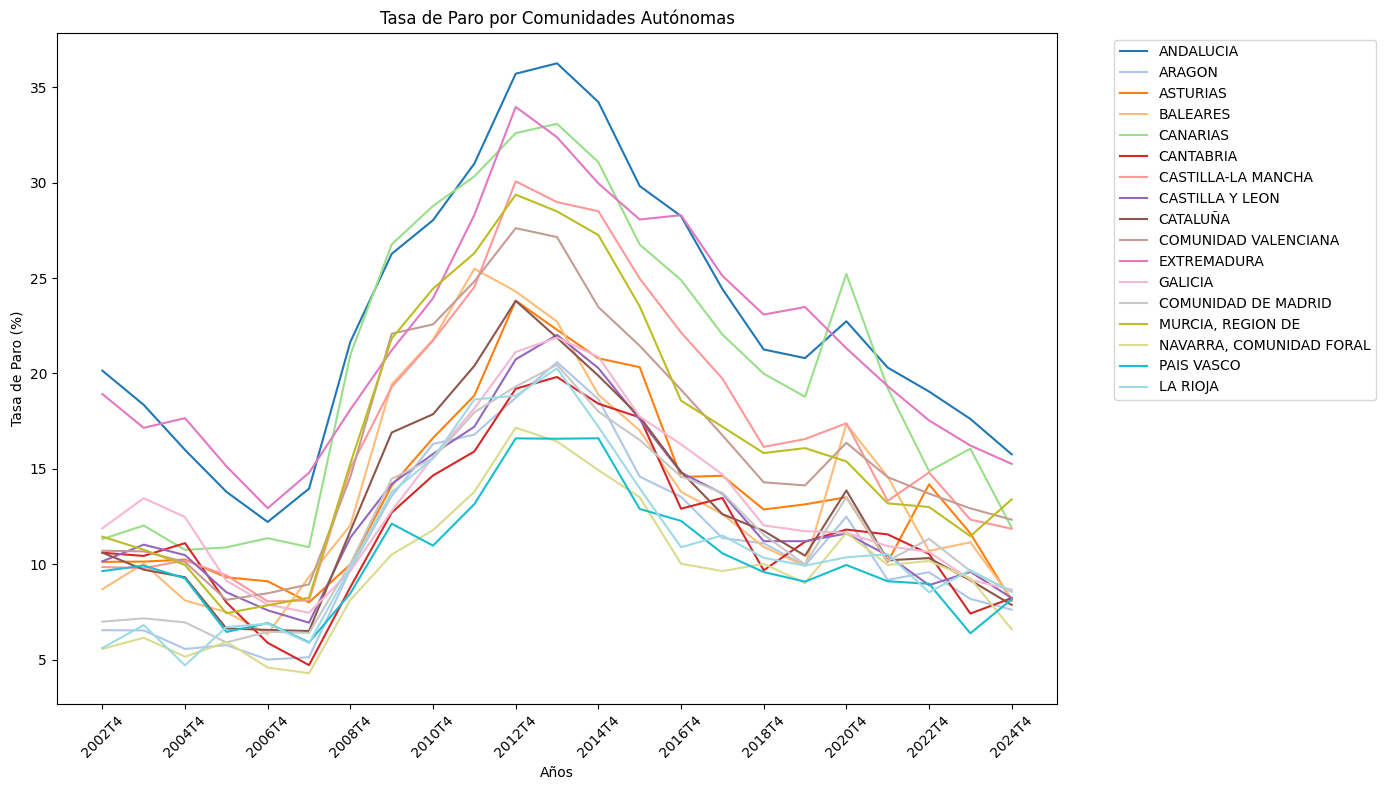

In [18]:
#Importamos los datos del apartado 6
data6=pd.read_excel(ruta, sheet_name='Datos apartado 6')

#Calculamos la tasa de paro para cada comunidad autónoma
data6_tasa_paro = pd.DataFrame()

#Creamos la lista de CCAA
lista_ccaa=[]
cols_activos = [c for c in data6.columns if c.startswith('ACTIVOS.')]
# Aladimos a la lista de nombres de CCAA limpiando el texto
lista_ccaa = [c.split('.')[1].strip().replace('\\', '') for c in cols_activos]

data6_tasa_paro['Año'] = data6['SERIES']
for ccaa in lista_ccaa:
    data6_tasa_paro[ccaa] = (data6[f'PARADOS. {ccaa}'] / data6[f'ACTIVOS. {ccaa}']) * 100

data6_tasa_paro = data6_tasa_paro.dropna().reset_index(drop=True)
data6_tasa_paro=data6_tasa_paro.iloc[3::4].reset_index(drop=True)  # Nos quedamos con los datos trimestrales

#Cambiamos el formato a AñoT
data6_tasa_paro['Año'] = data6_tasa_paro['Año'].astype(str)
years = data6_tasa_paro['Año'].str[:4]
trimestres = data6_tasa_paro['Año'].str[4:]
data6_tasa_paro['Año'] = years + 'T' + trimestres


#Hacemos el gráfico de la tasa de paro por comunidades autónomas
cmap = plt.get_cmap('tab20', len(lista_ccaa))
plt.figure(figsize=(14,8))
for i, ccaa in enumerate(lista_ccaa):
    plt.plot(data6_tasa_paro['Año'], data6_tasa_paro[ccaa], color= cmap(i),label=ccaa)
plt.xlabel('Años')
plt.ylabel('Tasa de Paro (%)')
plt.title('Tasa de Paro por Comunidades Autónomas')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(data6_tasa_paro['Año'].iloc[::2], rotation=45)
plt.tight_layout()
plt.show()

En este gráfico se ve fácilmente que las CCAA presentan patrones muy similares que tienen que ver con el comportamiento de la economía española a lo largo del periodo, aunque eso también hace que las dierencias entre las mismas persistan. En primer lugar las tasas de paro más altas las encontramos en Andalucía, Extremadura y Canarias, donde por ejemplo el COVID afectó especialmente a Canarias debido probablemente a la dependencia de dicha comunidad al turismo. En segundo lugar, las que menos suelen presentar son Navarra y País Vasco, seguramente por los altos niveles industriales que tienen, aunque sí es cierto que otras comunidades como Cantabria tienen niveles realmente similares.